In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv"

df = pd.read_csv(url)


5.5. Preguntas de análisis 

Con la información de la primera sección, se notó que existe una tendencia hacía las formas en que son comunicados los accidentes, al mismo tiempo, la gran mayoría de los accidentes parten de la misma naturaleza, así como las alcaldías que representaron la moda de incidentes. 

A continuación, se formulan cinco preguntas:
1. ¿Cuánto es el tiempo promedio entre la fecha_hora_creación de un folio con la fecha_hora_cierre del folio?
2. ¿Cómo son las distribuciones de robo entre las alcaldías?
3. Descartando de la variable tipo de entrada las llamadas del 911, ¿cómo se distribuyen los tipo de entrada entre las alcaldías?
4. ¿Cómo es la distribución de choques entre las alcaldias (incluyendo choques sin lesionados y con lesionados)?
5. ¿Cómo se distribuyen los códigos de cierre entre las alcaldías? 


5.6. Visualizaciones e interpretación 

In [3]:
df.head()

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C5/20220923/04016,2022-09-23 18:38:34,2022-09-23 22:22:27,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.443920
1,C5/20220829/00630,2022-08-29 02:56:31,2022-08-29 06:04:53,Accidente,Motociclista,CUAUHTEMOC,A,URGENCIAS MEDICAS,LLAMADA DEL 911,CUAUHTEMOC,Cuauhtémoc,Obrera,-99.140843,19.416669
2,C5/20220724/01907,2022-07-24 04:29:09,2022-07-24 07:36:49,Accidente,Choque sin lesionados,IZTAPALAPA,A,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,San Andres Tetepilco,-99.130702,19.371340
3,C5/20240215/03071,2024-02-15 16:20:03,2024-02-15 20:52:19,Accidente,Choque sin lesionados,LA MAGDALENA CONTRERAS,A,EMERGENCIA,LLAMADA DEL 911,LA MAGDALENA CONTRERAS,La Magdalena Contreras,La Cruz,-99.233973,19.305985
4,C5/20221006/03493,2022-10-06 19:33:05,2022-10-06 22:37:08,Accidente,Choque sin lesionados,IZTAPALAPA,F,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Santa Martha Acatitla Norte,-99.013140,19.374476


1. ¿Cuánto es el tiempo promedio entre la fecha_hora_creación de un folio con la fecha_hora_cierre del folio?

In [8]:
df["fecha_hora_creacion"] = pd.to_datetime(df["fecha_hora_creacion"])
df["fecha_hora_cierre"] = pd.to_datetime(df["fecha_hora_cierre"])

In [9]:
# Tiempo transcurrido en minutos
df["tiempo_cierre_min"] = (
    df["fecha_hora_cierre"] - df["fecha_hora_creacion"]
).dt.total_seconds() / 60

# Tiempo de cierre
df["tiempo_cierre_min"].describe()

count    124261.000000
mean        263.640030
std         300.417581
min           0.383333
25%         184.150000
50%         187.650000
75%         191.433333
max        4600.166667
Name: tiempo_cierre_min, dtype: float64

Text(0, 0.5, 'Número de reportes (escala log)')

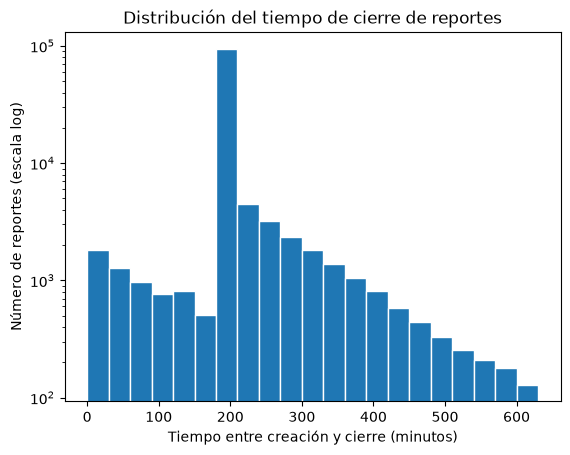

In [17]:
import numpy as np  # Crear los intervalos de tiempo.
import matplotlib.pyplot as plt # Crear y personalizar la gráfica.

bins = np.arange(0, 631, 30) # Define intervalos de 30 minutos.
plt.hist(df["tiempo_cierre_min"].dropna(), bins=bins, edgecolor="white")# Grafica la frecuencia de los tiempos de cierre.
plt.yscale("log")
plt.title("Distribución del tiempo de cierre de reportes")
plt.xlabel("Tiempo entre creación y cierre (minutos)")
plt.ylabel("Número de reportes (escala log)")


En la gráfica se observa que la mayoría de los reportes se concentran entre los 200 y 250 minutos. A medida que aumenta el tiempo de cierre, disminuye el número de reportes. Se utilizó una escala logarítmica en el eje vertical para facilitar la visualización de las diferencias.

2. ¿Cómo se distribuyen los reportes clasificados como falsas alarmas entre las alcaldías de la Ciudad de México?

In [18]:
# Reportes clasificados como falsas alarmas
df_falsas_alarmas = df[
    df["clas_con_f_alarma"] == "FALSA ALARMA"
]

In [19]:
conteo_falsas_alarmas = df_falsas_alarmas["alcaldia_catalogo"].value_counts()

Text(0, 0.5, 'Número de reportes')

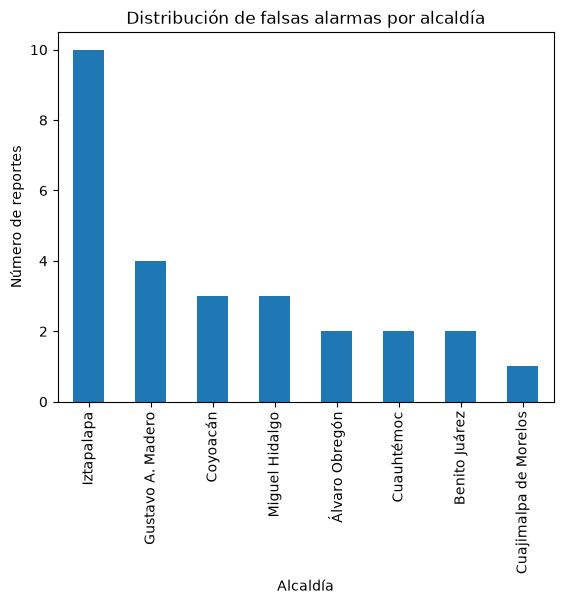

In [20]:
conteo_falsas_alarmas.plot(kind="bar")  # kind=bar: crear las barras para comparara las categorías
plt.title("Distribución de falsas alarmas por alcaldía")
plt.xlabel("Alcaldía")
plt.ylabel("Número de reportes")

Se observa que Iztapalapa tiene el amyor número de falsas alarma, con 10 reportes, seguido de Gustavo A. 
Madero, con 4, mientras que Coyoacán y Miguel Hidalgo tienen 3 reportes cada una. El resto de alcaldías tienen entre 1 y 2 reportes. Esto nos indica que Iztapalapa tiene la mayor concentración de falsas alarmas. 

3. Descartando de la variable tipo de entrada las llamadas del 911, ¿cómo se distribuyen los tipo de entrada entre las alcaldías?

In [30]:
# Excluir las llamadas del 911
df_otros_canales = df[df["tipo_entrada"] != "LLAMADA DEL 911"]


In [31]:
tabla_entradas = pd.crosstab( #crea una tabla cruzada, cuántos registros x cada variable
    df_otros_canales["alcaldia_catalogo"],
    df_otros_canales["tipo_entrada"]
)

Text(0, 0.5, 'Alcaldía')

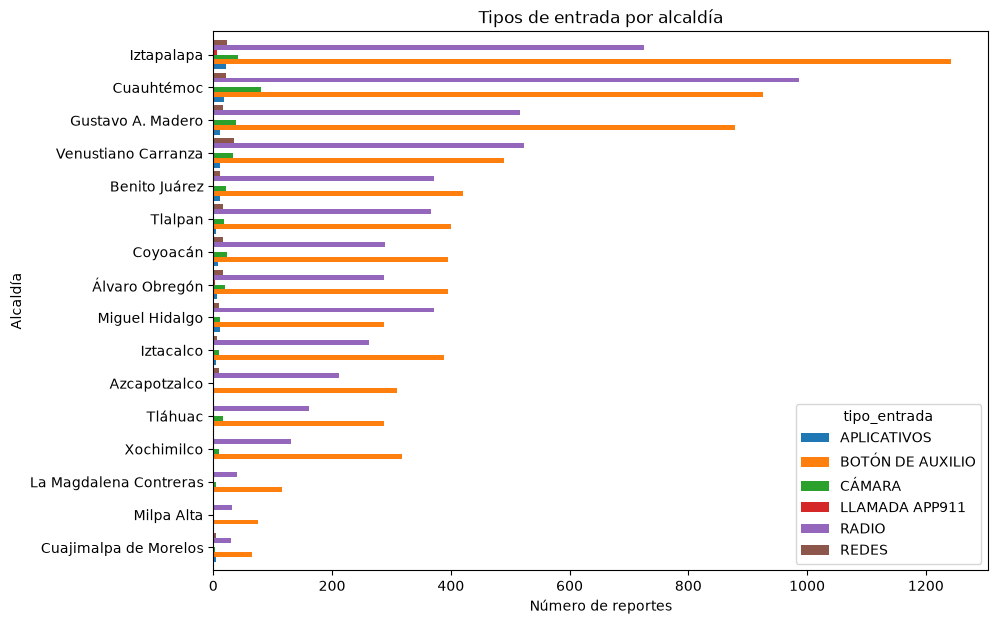

In [37]:
tabla_ordenada = tabla_entradas.loc[ # Ordenar las alcaldías por número total de reportes para una mejor visualización 
    tabla_entradas.sum(axis=1).sort_values().index
]

tabla_ordenada.plot(kind="barh",figsize=(10, 7), width=0.9) #width: aumentar el grosor de las barras
plt.title("Tipos de entrada por alcaldía") #figsize: establece el ancho y el alto del gráfico.
plt.xlabel("Número de reportes")
plt.ylabel("Alcaldía")

Los resultados muestran que los botones de auxilio y la radio son los tipos de entrada con más reportes, siendo Iztapalapa la principal figura. En contra parte, Cuajimalpa,  tiene el menor núemor de reportes. 

4.¿Cómo es la distribución de choques entre las alcaldías, incluyendo choques sin lesionados y con lesionados?

In [38]:
# Seleccionar los reportes de choques
df_choques = df[ #revisar la descripción del inicdente
    df["incidente_c4"].isin([ #selecciona las filas que coinciden con esos dos tipos de choques 
        "Choque sin lesionados",
        "Choque con lesionados"
    ])
]

In [39]:
# Choques por alcaldía y tipo de incidente
tabla_choques = pd.crosstab( #cuenta cuántos reportes hay en cada combinación
    df_choques["alcaldia_catalogo"],
    df_choques["incidente_c4"]
)

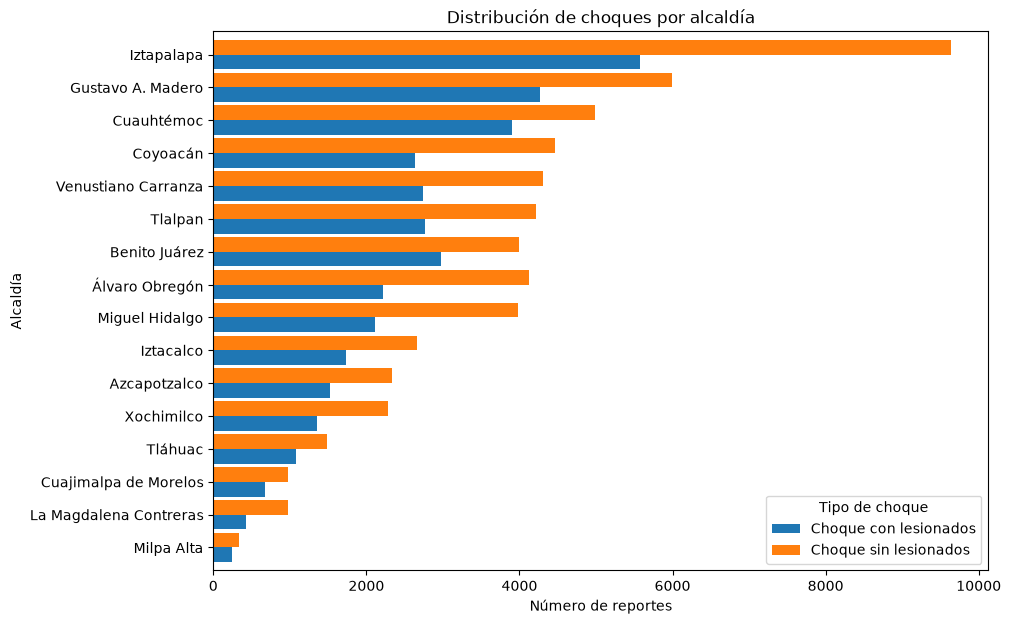

In [41]:
tabla_choques_ordenada = tabla_choques.loc[
    tabla_choques.sum(axis=1).sort_values().index
]
tabla_choques_ordenada.plot(kind="barh", figsize=(10, 7), width=0.9)
plt.title("Distribución de choques por alcaldía")
plt.xlabel("Número de reportes")
plt.ylabel("Alcaldía")
plt.legend(title="Tipo de choque")

Iztapalapa concentra más reportes de choques, tanto con lesionados como sin lesionados. En general, predominan los accidentes sin lesionados, y también destacan Gustavo A. Madero y Venustiano Carranza por su alta incidencia. En contra parte de Milpa Alta que tiene el menor número de incidencias. 

5. ¿Cómo se distribuyen los códigos de cierre entre las alcaldías?

In [44]:
tabla_cierre = pd.crosstab(df["alcaldia_catalogo"], df["codigo_cierre"])

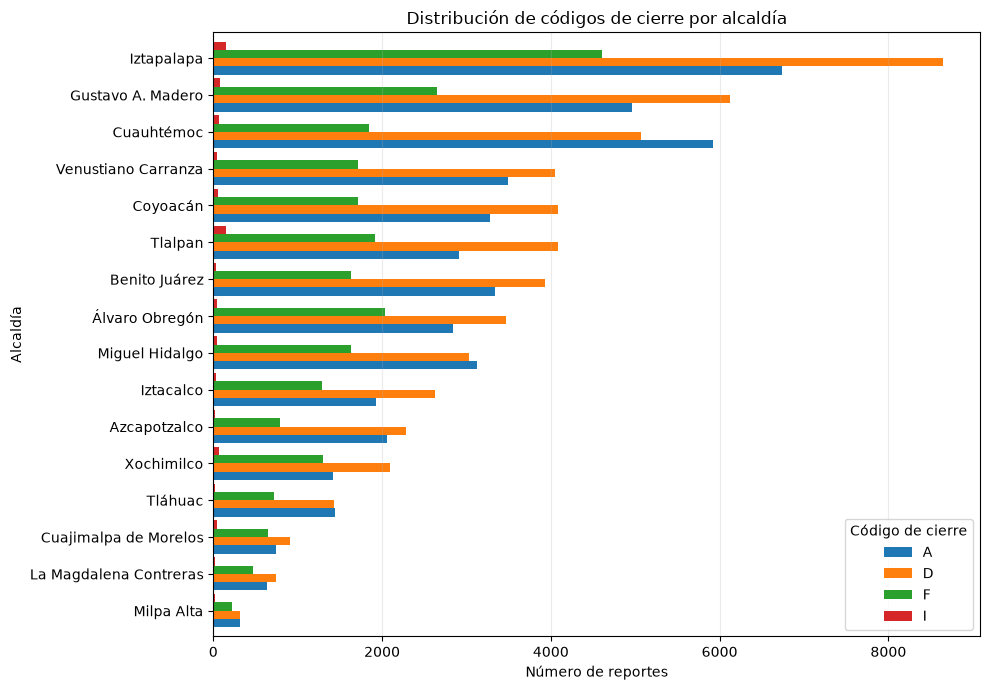

In [46]:
tabla_cierre_ordenada = tabla_cierre.loc[
    tabla_cierre.sum(axis=1).sort_values().index
]
tabla_cierre_ordenada.plot(kind="barh", figsize=(10, 7), width=0.9)
plt.title("Distribución de códigos de cierre por alcaldía")
plt.xlabel("Número de reportes")
plt.ylabel("Alcaldía")
plt.legend(title="Código de cierre")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()




La gráfica muestra que Iztapalapa registra más reportes, seguida de Gustavo A. Madero y Cuauhtémoc. En casi todas las alcaldías domina el código de cierre D, mientras que el I aparece mucho menos. Además, en zonas como La Magdalena Contreras y Milpa Alta el número de reportes baja bastante.

In [48]:
import pandas as pd
print(pd.__version__)

3.1.0
